[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L5/BA_L5_dpi/BA_L5_dpi.ipynb)

# BA_L5_dpi: The De-pegging Pressure Index

*Quantlet of Lecture 5, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

The De-pegging Pressure Index (DPI), the mean penalty selected by generalised approximate cross-validation (GACV) in rolling 90-day 5% Quantile Lasso equations of 10 stablecoins, April 2020 - October 2026 (EODHD data), coloured by quintile, with six stress events, annual medians and a log-linear trend with heteroskedasticity and autocorrelation consistent (HAC) standard errors. Estimated every 7th day by default; set FULL_DAILY = True for the daily index of the lecture.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

## The De-pegging Pressure Index, April 2020 – October 2026

**Reference adjustment.** Let $P_{i,t}$ be the dollar price of token $i$ and $B_{i,t}$ the dollar value of its reference asset ($B = 1$ for dollar tokens, EUR/USD for STASIS Euro (EURS), XAU/USD for Pax Gold (PAXG)). The reference-adjusted deviation, in basis points (bp, 0.01%), is
$$ d_{i,t} = 10^4\left(\frac{P_{i,t}}{B_{i,t}} - 1\right). $$
Prices are put on a calendar of all days and filled from the past for at most 7 days; a daily move beyond 1,000 bp that reverses by at least 90% the next day is treated as a recording error and removed.

**The De-pegging Pressure Index (DPI).** For each coin $j$ and day $t$, a 5% Quantile Lasso on the 90 days before $t$: the target is $d_{j,s}$; the predictors are the other coins' $d_{k,s}$ (same day) and the one-day-lagged changes of the US dollar index (DXY), the CBOE volatility index (VIX), the S&P 500 index (log changes) and the 1-year Treasury yield (first differences).
Every variable is centred by its window median and divided by $1.4826 \times$ its median absolute deviation (MAD). With the check loss $\rho_\tau(e) = e\,(\tau - \mathbb 1\{e < 0\})$,
$$ (\hat\alpha, \hat\beta)(\lambda) = \arg\min_{\alpha, \beta} \sum_{s \in W_t} \rho_{0.05}\big(d_{j,s} - \alpha - \mathbf x_{j,s}'\beta\big) + \lambda \sum_k |\beta_k| , $$
and $\hat\lambda_{j,t}$ minimises the generalised approximate cross-validation (GACV) criterion $\sum_s \rho_\tau(\hat e_s) / (n - \mathrm{df})$, $\mathrm{df} = \#\{\hat\beta_k \neq 0\} + 1$, over 25 values from $10^{-4}\lambda_{max}$ to $\lambda_{max}$. The index is the average selected penalty:
$$ \mathrm{DPI}_t = \frac{1}{J}\sum_{j=1}^{J} \hat\lambda_{j,t} . $$
The DPI is not a depeg probability; it is a model-implied measure of lower-tail dependence. Method of Fan, Sha, Härdle & Pele (2026); the penalty as a risk measure comes from the Financial Risk Meter (FRM) of [Mihoci, Althof, Chen & Härdle (2020)](https://doi.org/10.1108/S0731-905320200000042016).

**Computation.** The daily index of the lecture (2,397 days, 23,970 equations, about 600,000 linear programmes) takes from a few minutes on many processor cores to more than half an hour on two.
This Quantlet estimates the DPI **every 7th day** (the 342 days before the weekly portfolio rebalancings), which takes 1–3 minutes.
The chart has the same shape; numbers that average over days (medians, shares, the trend) differ slightly from the slide, which uses every day.
Set `FULL_DAILY = True` to estimate every day and reproduce the slide numbers exactly.

**How to read the chart.** Points are coloured by the quintile of the DPI (the five 20% bands of its distribution, from "low" to "severe"); dotted lines mark six stress events; the dashed line is the end of the paper's sample (31 May 2026). Log scale.

In [4]:
# Data: 10 stablecoins, their reference assets and four market variables, 1 January 2020 - 23 October 2026
import matplotlib
plt.rcParams['font.size'] = 10
END, END_PAPER = '2026-10-23', '2026-05-31'          # last day of the lecture sample; last day of the paper's sample
COINS = ['USDT', 'USDC', 'DAI', 'TUSD', 'USDP', 'GUSD', 'BUSD', 'SUSD', 'PAXG', 'EURS']
cal = pd.date_range('2020-01-01', END)


def weekdays(x):
    """EUR/USD and gold: Monday-Friday closes, repeated closes removed (the weekend bars come from a thin session)."""
    x = x[x.index.dayofweek < 5]
    return x[x.diff() != 0]


def finish_fig(fig, name, bottom, ncol=3):
    """Legend below the plot, then save and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)


ref = {'EURS': weekdays(daily('EURUSD.FOREX', END)), 'PAXG': weekdays(daily('XAUUSD.FOREX', END))}
P = pd.DataFrame({c: daily(f'{c}-USD.CC', END) for c in COINS}).reindex(cal).ffill(limit=7)    # past-only fill, at most 7 days
lr = 1e4 * np.log(P).diff()
bad = (lr.abs() > 1000) & (-lr.shift(-1) / lr >= 0.9)      # bad print: a move beyond 1000 bp, reversed by >= 90% the next day
P_raw = P.copy()                                           # prices as recorded
P = P.mask(bad).ffill(limit=7)                             # retrospective cleaning
Bm = pd.DataFrame({c: (ref[c].reindex(cal).ffill() if c in ref else pd.Series(1.0, index=cal)) for c in COINS})
D = 1e4 * (P / Bm - 1)                                     # reference-adjusted deviation d (bp)
D_raw = 1e4 * (P_raw / Bm - 1)                             # same, prices as recorded
R = 1e4 * np.log(P / Bm).diff()                            # reference-adjusted log return (bp)
mac = pd.DataFrame({'DXY': daily('DXY.INDX', END), 'VIX': daily('VIX.INDX', END), 'SPX': daily('GSPC.INDX', END),
                    'US1Y': daily('US1Y.GBOND', END)}).reindex(cal).ffill()
M = pd.DataFrame({'DXY': np.log(mac['DXY']).diff(), 'VIX': np.log(mac['VIX']).diff(), 'SPX': np.log(mac['SPX']).diff(),
                  'US1Y': mac['US1Y'].diff()}).shift(1)     # market changes, lagged one day
print(f'calendar {cal[0].date()} to {cal[-1].date()} ({len(cal)} days); bad prints removed: {int(bad.values.sum())}')

calendar 2020-01-01 to 2026-10-23 (2488 days); bad prints removed: 9


In [5]:
# 5% Quantile Lasso, penalty chosen by GACV, one equation per coin and day
from scipy.optimize import linprog
from joblib import Parallel, delayed
TAU, WIN, NGRID, LO = 0.05, 90, 25, 1e-4      # quantile level, window (days), grid size, lowest penalty / lambda_max
N_JOBS = os.cpu_count() or 1


def rho(e, tau=TAU):
    """Check loss."""
    return e * (tau - (e < 0))


def qlasso(X, y, lam):
    """Quantile Lasso as a linear programme: y = a+ - a- + X(b+ - b-) + u - v, minimise lam |b| + tau u + (1 - tau) v."""
    n, p = X.shape
    c = np.concatenate([[0, 0], lam * np.ones(2 * p), TAU * np.ones(n), (1 - TAU) * np.ones(n)])
    A = np.hstack([np.ones((n, 1)), -np.ones((n, 1)), X, -X, np.eye(n), -np.eye(n)])
    z = linprog(c, A_eq=A, b_eq=y, bounds=[(0, None)] * len(c), method='highs').x
    return z[0] - z[1], z[2:2 + p] - z[2 + p:2 + 2 * p]


def robust(Z):
    """Centre by the median, divide by 1.4826 x MAD (by the sd if the MAD is zero); drop constant columns."""
    med = np.median(Z, axis=0)
    mad = 1.4826 * np.median(np.abs(Z - med), axis=0)
    s = np.where(mad > 0, mad, Z.std(axis=0))
    keep = s > 0
    return (Z[:, keep] - med[keep]) / s[keep], keep


def fit_eq(y, X, lo=LO):
    """GACV-selected penalty on 25 values in [lo, 1] x lambda_max: returns (lambda, GACV, slopes, grid position)."""
    n = len(y)
    if X.shape[1] == 0:
        return np.nan, rho(y - np.quantile(y, TAU)).sum() / (n - 1), np.array([]), -1
    lmax = np.abs(X.T @ (TAU - (y < np.quantile(y, TAU)))).max()
    best = None
    for k, lam in enumerate(np.geomspace(lmax * lo, lmax, NGRID)):
        a, b = qlasso(X, y, lam)
        df = 1 + (np.abs(b) > 1e-8).sum()
        g = rho(y - a - X @ b).sum() / (n - df)
        if best is None or g < best[1]:
            best = (lam, g, b, k)
    return best


def window(t_idx):
    """Deviations of the 90 days before day t as known on day t: cleaned, except the last day (not yet checkable)."""
    Dw = D.iloc[t_idx - WIN:t_idx].copy()
    Dw.iloc[-1] = D_raw.iloc[t_idx - 1]
    return Dw


def day(t_idx, blocks=('coin', 'macro'), lo=LO):
    """All coin equations of calendar row t_idx: target d_j, predictors the other coins' d and the lagged market changes."""
    Dw = window(t_idx)
    out = {}
    for c in COINS:
        y = Dw[c].values
        if np.isnan(y).any():
            continue
        y = (y - np.median(y)) / (1.4826 * np.median(np.abs(y - np.median(y))) or y.std() or 1)
        parts, names = [], []
        if 'coin' in blocks:
            Xc = Dw.drop(columns=c)
            ok = ~np.isnan(Xc.values).any(axis=0)
            parts.append(Xc.values[:, ok]); names += list(Xc.columns[ok])
        if 'macro' in blocks:
            parts.append(M.values[t_idx - WIN:t_idx]); names += list(M.columns)
        Zs, keep = robust(np.hstack(parts))
        names = [nm for nm, k in zip(names, keep) if k]
        lam, g, b, k = fit_eq(y, Zs, lo)
        out[c] = dict(lam=lam, gacv=g, k=k, coef=dict(zip(names, b)))
    return t_idx, out


def run_days(idx, lo=LO):
    """Estimate all equations on the calendar rows idx, in parallel on all processor cores."""
    chunks = [c for c in np.array_split(np.asarray(idx), 4 * N_JOBS) if len(c)]
    out = Parallel(n_jobs=N_JOBS)(delayed(lambda ix: [day(i, lo=lo) for i in ix])(c) for c in chunks)
    return {i: o for part in out for i, o in part}


first = cal.get_loc(pd.Timestamp('2020-04-01'))           # first DPI day: 90 days of history
weekly = [i for i in range(first, len(cal)) if (cal[i] - pd.Timestamp('2020-06-29')).days % 7 == 0]   # days before the rebalancings

In [6]:
EVENTS = {'KuCoin hack': '2020-09-26', 'China sell-off': '2021-05-19', 'Terra collapse': '2022-05-09',
          'FTX crisis': '2022-11-08', 'SVB / USDC depeg': '2023-03-11', 'Iran-Hormuz shock': '2026-02-28'}

import time
FULL_DAILY = False                                          # True: every day, as on the slides (slower)
idx = list(range(first, len(cal))) if FULL_DAILY else weekly
t0 = time.time()
res = run_days(idx)
print(f'{len(idx)} days x {len(COINS)} coins estimated in {time.time() - t0:.0f} s')
LAM = pd.DataFrame({cal[i]: {c: v['lam'] for c, v in o.items()} for i, o in res.items()}).T[COINS].sort_index()
DPI = LAM.mean(axis=1)                                      # DPI_t = mean selected penalty over the coins
FREQ = 'daily' if FULL_DAILY else 'weekly'
print(f'DPI: {len(DPI)} {FREQ} values, {DPI.index[0].date()} to {DPI.index[-1].date()}; median {DPI.median():.3f}')

342 days x 10 coins estimated in 32 s
DPI: 342 weekly values, 2020-04-06 to 2026-10-19; median 0.391


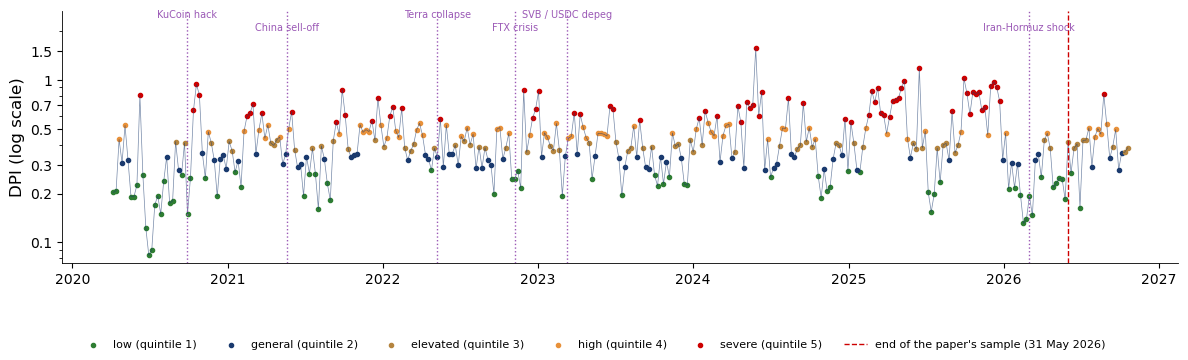

In [7]:
fig, ax = plt.subplots(figsize=(12, 3.6))
qs_ = DPI.quantile([0.2, 0.4, 0.6, 0.8]).values
cats = np.digitize(DPI.values, qs_)
qcols = [GREEN, BLUE, GOLD, BTC, RED]; labs = ['low', 'general', 'elevated', 'high', 'severe']
ax.plot(DPI.index, DPI.values, color=BLUE, lw=0.5, alpha=0.6)
for k in range(5):
    m = cats == k
    ax.scatter(DPI.index[m], DPI.values[m], s=4 if FULL_DAILY else 9, color=qcols[k], label=f'{labs[k]} (quintile {k + 1})')
for k_, (name, d0) in enumerate(EVENTS.items()):
    ax.axvline(pd.Timestamp(d0), color=ETH, ls=':', lw=1)
    ax.text(pd.Timestamp(d0), DPI.max() * (1.25 if k_ % 2 else 1.5), name, fontsize=7, color=ETH, ha='center', va='bottom')
ax.axvline(pd.Timestamp(END_PAPER), color=RED, ls='--', lw=1, label="end of the paper's sample (31 May 2026)")
ax.set_yscale('log'); ax.set_ylabel('DPI (log scale)'); ax.set_ylim(DPI.min() * 0.9, DPI.max() * 1.7)
ax.set_yticks([t for t in [0.1, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5] if DPI.min() * 0.9 <= t <= DPI.max() * 1.7])
ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%g')); ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
finish_fig(fig, 'ba_l5_dpi', 0.15, ncol=6)

**Annual medians and trend.** We regress $\ln \mathrm{DPI}_t$ on time in years up to May 2026, with heteroskedasticity and autocorrelation consistent (HAC) standard errors (SE) and a lag window of about 90 days (90 daily or 13 weekly observations).
The last column gives the values of the daily index shown on the slides.

In [8]:
import statsmodels.api as sm
ld_ = np.log(DPI.loc[:END_PAPER])
tt = (ld_.index - ld_.index[0]).days.values / 365.25
trd = sm.OLS(ld_.values, sm.add_constant(tt)).fit(cov_type='HAC', cov_kwds={'maxlags': 90 if FULL_DAILY else 13})
ci_ = trd.conf_int(0.05)[1]
tab = pd.DataFrame({'this run': {**{f'median DPI {y_}': v for y_, v in DPI.groupby(DPI.index.year).median().items()},
                                 'trend of log DPI (per year)': trd.params[1], 'HAC SE of the trend': trd.bse[1],
                                 'p-value of the trend': trd.pvalues[1], '95% CI, lower': ci_[0], '95% CI, upper': ci_[1]}})
tab['daily DPI (slides)'] = [0.27, 0.39, 0.40, 0.39, 0.44, 0.52, 0.32, 0.046, 0.036, 0.21, -0.025, 0.117]
print(f'DPI computed {FREQ}; paper: trend -0.004 per year, p-value 0.78')
tab.round(3)

DPI computed weekly; paper: trend -0.004 per year, p-value 0.78


,this run,daily DPI (slides)
median DPI 2020,0.262,0.270
median DPI 2021,0.414,0.390
median DPI 2022,0.389,0.400
median DPI 2023,0.386,0.390
median DPI 2024,0.418,0.440
median DPI 2025,0.572,0.520
median DPI 2026,0.339,0.320
trend of log DPI (per year),0.044,0.046
HAC SE of the trend,0.038,0.036
p-value of the trend,0.243,0.210


The DPI moves in regimes; its highest regime in late 2025 coincides with the start of the sUSD depeg. A zero slope is not rejected, but the 95% interval is wide, so this is not evidence of no trend.